# Thesis Fig. 6 — kernel families against the Wiener optimum

Reproduction of Tepper (2026), Fig. 6 (thesis PDF p. 81; printed p. 74), panel by panel.

> Top: physical-space profiles of narrow Gaussian, wide Gaussian, box, B-spline (p = 1) and the Wiener-optimal
> kernel. Bottom: readout against target for each, with RMSE. The optimum allocates spectral energy by the target PSD
> and the regularization scale and gives much lower error.

**Panels:** A kernel profiles · B readout vs target · C (added) spectra and expected error at equal budget.

**Acceptance (spec 6A.6):** the optimum's error is ≤ every family's at equal budget.

**Parameters [D11]:** `configs/thesis/fig6.yaml`. All kernels are rescaled to the same K0. The Wiener kernel is
eq. 7.13 with positive signs (§6.12 sign policy), T_obs = N.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seqnet.thesis as th
from seqnet.thesis.figures import load_config, save_data, load_data, save_figure, record_checks, style

style()
FIG = "fig6"
cfg = load_config(FIG)
N, decay = cfg["N"], cfg["decay"]
K0 = N * cfg["K0_per_mode"]
ring, sched = th.Ring(N), th.Schedule(N, 1)
tg = cfg["target"]
tc = th.TargetClass.narrowband(N // 2 - 1, xi0=tg["xi0"], ell=tg["ell"])
S = np.concatenate([tc.psd, [0.0]])
fams = {lab: th.Kernel.from_family(f, N, **p) for lab, (f, p) in cfg["families"].items()}
fams = {lab: th.Kernel(values=k.values * np.sqrt(K0 / k.energy())) for lab, k in fams.items()}
wf = th.water_fill(S, decay, K0, N=N)
kernels = dict(fams, **{"Wiener optimal": th.Kernel.from_alloc(wf.a, N)})
LABELS = list(kernels)
{lab: round(k.energy(), 6) for lab, k in kernels.items()}, wf.M_star, wf.nu

({'Narrow Gaussian': 128.0,
  'Wide Gaussian': 128.0,
  'Box': 128.0,
  'B-spline p=1': 128.0,
  'Wiener optimal': 128.0},
 22,
 4.5019213674955005e-05)

## Panel A — kernel profiles (peak-normalized for display)

In [2]:
save_data(FIG, "A_kernels", params={"K0": K0, "families": cfg["families"]}, r=ring.centred_positions,
          K=np.stack([k.values for k in kernels.values()]))

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig6/A_kernels.npz')

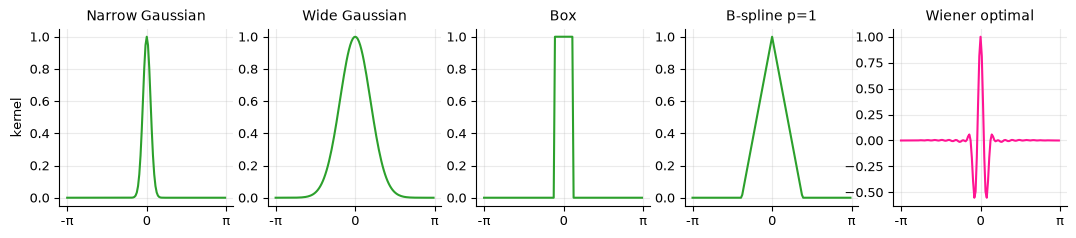

In [3]:
d = load_data(FIG, "A_kernels"); o = np.argsort(d["r"])
fig, axs = plt.subplots(1, 5, figsize=(13, 2.3))
for ax, kv, lab in zip(axs, d["K"], LABELS):
    ax.plot(d["r"][o], kv[o] / np.abs(kv).max(), color="deeppink" if lab == "Wiener optimal" else "tab:green")
    ax.set_title(lab); ax.set_xticks([-np.pi, 0, np.pi], ["-π", "0", "π"])
axs[0].set_ylabel("kernel")
save_figure(FIG, "A_kernels", fig); plt.show()

## Panel B — readout against target (one random-phase draw; RMSE over the N positions)

In [4]:
rng = np.random.default_rng(cfg["seed"])
y = tc.sample(rng, N, sched.positions)
YH, RMSE = [], []
for k in kernels.values():
    X = th.design_matrix(k, sched)
    yh = X @ th.ridge_readout(X, y, decay)
    YH.append(yh); RMSE.append(np.sqrt(np.mean((yh - y) ** 2)))
save_data(FIG, "B_readout", c=ring.centred_positions, y=y, YH=np.stack(YH), RMSE=np.array(RMSE), figure=np.array(cfg["figure_rmse"]))

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig6/B_readout.npz')

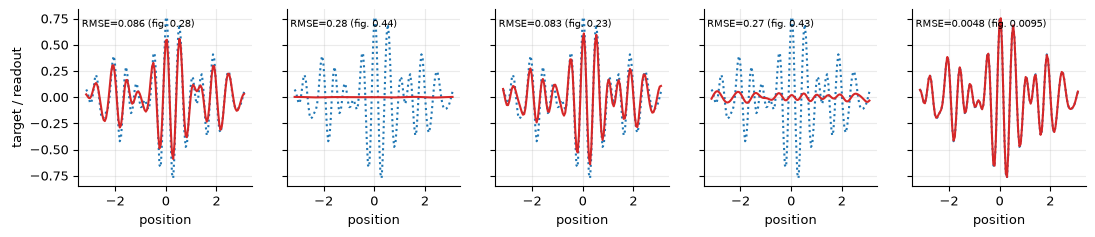

In [5]:
d = load_data(FIG, "B_readout"); o = np.argsort(d["c"])
fig, axs = plt.subplots(1, 5, figsize=(13, 2.3), sharey=True)
for ax, yh, r, f, lab in zip(axs, d["YH"], d["RMSE"], d["figure"], LABELS):
    ax.plot(d["c"][o], d["y"][o], ":", color="tab:blue"); ax.plot(d["c"][o], yh[o], color="tab:red")
    ax.text(0.02, 0.9, f"RMSE={r:.2g} (fig. {f})", transform=ax.transAxes, fontsize=7); ax.set_xlabel("position")
axs[0].set_ylabel("target / readout")
save_figure(FIG, "B_readout", fig); plt.show()

## Panel C (added) — allocations and expected within-band error at equal budget

E_bias (eq. 6.7) for each kernel's allocation against the target class, and every allocation plotted against S(m).

In [6]:
A = np.stack([k.alloc() for k in kernels.values()])
E = np.array([th.error_terms(a, S, decay, N, N).bias for a in A])
E_min = th.min_bias_error(wf, S)
save_data(FIG, "C_allocations", m=np.arange(N // 2 + 1), A=A, S=S, E=E, E_min=E_min)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig6/C_allocations.npz')

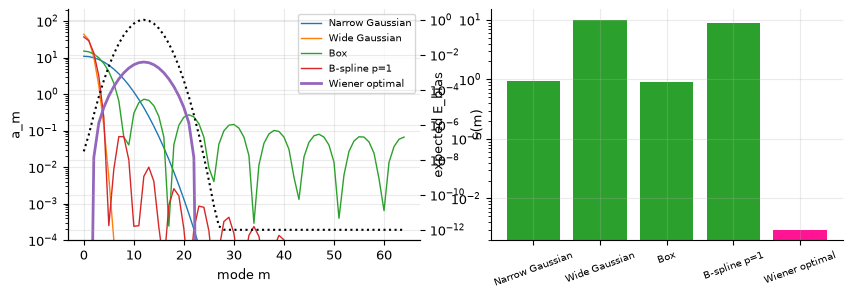

{'Narrow Gaussian': np.float64(0.95503), 'Wide Gaussian': np.float64(10.02539), 'Box': np.float64(0.88827), 'B-spline p=1': np.float64(8.99703), 'Wiener optimal': np.float64(0.00298)} eq. 7.17: 0.002976913498910115


In [7]:
d = load_data(FIG, "C_allocations")
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3))
for a, lab in zip(d["A"], LABELS):
    ax.semilogy(d["m"], a + 1e-12, label=lab, lw=2 if lab == "Wiener optimal" else 1)
ax2_ = ax.twinx(); ax2_.semilogy(d["m"], d["S"] + 1e-12, "k:", label="S(m)"); ax2_.set_ylabel("S(m)")
ax.set_ylim(1e-4, None); ax.set_xlabel("mode m"); ax.set_ylabel("a_m"); ax.legend(fontsize=7)
ax2.bar(range(len(LABELS)), d["E"], color=["tab:green"] * 4 + ["deeppink"]); ax2.set_yscale("log")
ax2.set_xticks(range(len(LABELS)), LABELS, rotation=20, fontsize=7); ax2.set_ylabel("expected E_bias")
save_figure(FIG, "C_allocations", fig); plt.show()
print(dict(zip(LABELS, np.round(d["E"], 5))), "eq. 7.17:", float(d["E_min"]))

## Acceptance

In [8]:
c = load_data(FIG, "C_allocations"); b = load_data(FIG, "B_readout")
checks = [
    {"item": "optimum error <= every family at equal budget (expected E_bias)", "criterion": "E_opt <= min(E_family)",
     "value": {"E_opt": float(c["E"][-1]), "E_families_min": float(c["E"][:-1].min())}, "passed": bool(c["E"][-1] <= c["E"][:-1].min())},
    {"item": "eq. 7.17 equals E_bias at the optimum", "criterion": "relative difference < 1e-9",
     "value": float(abs(c["E"][-1] - c["E_min"]) / c["E_min"]), "passed": bool(abs(c["E"][-1] - c["E_min"]) / c["E_min"] < 1e-9)},
    {"item": "single-draw RMSE: optimum lowest (as in the figure)", "criterion": "argmin RMSE = Wiener",
     "value": {"reproduced": b["RMSE"], "figure": b["figure"]}, "passed": bool(np.argmin(b["RMSE"]) == len(LABELS) - 1)},
]
record_checks(FIG, checks)
for ch in checks: print(ch)

{'item': 'optimum error <= every family at equal budget (expected E_bias)', 'criterion': 'E_opt <= min(E_family)', 'value': {'E_opt': 0.0029769134989101123, 'E_families_min': 0.8882681902821308}, 'passed': True}
{'item': 'eq. 7.17 equals E_bias at the optimum', 'criterion': 'relative difference < 1e-9', 'value': 8.74088284700871e-16, 'passed': True}
{'item': 'single-draw RMSE: optimum lowest (as in the figure)', 'criterion': 'argmin RMSE = Wiener', 'value': {'reproduced': array([0.08637791, 0.27986317, 0.08330423, 0.2651213 , 0.00482257]), 'figure': array([0.28  , 0.44  , 0.23  , 0.43  , 0.0095])}, 'passed': True}
